# Lab 2 — Unsupervised Cybersecurity Analytics with K-Means and DBSCAN

**Scenario:** You are a SOC analyst exploring network connections. Labels are hidden during clustering: can unsupervised learning reveal groups of normal traffic, attacks, or unusual connections?

**Dataset:** KDD Cup 1999, official UCI archive. The notebook uses scikit-learn to download the 10% subset, then samples a manageable subset for classroom use. The dataset is historical/simulated network traffic, not modern production telemetry. Source: https://archive.ics.uci.edu/dataset/130/kdd%2Bcup%2B1999%2Bdata


> Learning rule: do not use the attack label to train clustering. We keep it aside only for a final, cautious evaluation. A cluster is not automatically an attack label.

## Step 1 — Set up the environment

The notebook is designed to run in Google Colab.

Run the cells in order, from top to bottom. If you restart the runtime, run the setup and data-loading cells again before continuing.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_kddcup99
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

RANDOM_STATE = 42
print("Environment ready.")

Libraries loaded


## Step 2 — Load and inspect the real dataset

KDD Cup 1999 is a classic intrusion-detection benchmark with simulated normal connections and multiple attack types. We sample 5,000 rows to keep this lab interactive. The binary label is **not** included in the features used by the clustering algorithms.

In [ ]:
data = fetch_kddcup99(percent10=True, shuffle=True, random_state=RANDOM_STATE, as_frame=True)
df = data.frame.copy()
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (494021, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,labels
0,0,b'icmp',b'ecr_i',b'SF',1032,0,0,0,0,0,...,255,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,b'smurf.'
1,0,b'icmp',b'ecr_i',b'SF',1032,0,0,0,0,0,...,255,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,b'smurf.'
2,0,b'icmp',b'ecr_i',b'SF',1032,0,0,0,0,0,...,255,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,b'smurf.'
3,0,b'tcp',b'http',b'SF',345,5419,0,0,0,0,...,255,1.0,0.0,0.01,0.02,0.0,0.0,0.0,0.0,b'normal.'
4,0,b'tcp',b'private',b'S0',0,0,0,0,0,0,...,2,0.01,0.07,0.0,0.0,1.0,1.0,0.0,0.0,b'neptune.'


### Inspect the target and class imbalance

The target is used only after clustering to discuss whether discovered groups align with normal/attack labels.

In [ ]:
target_col = "labels" if "labels" in df.columns else df.columns[-1]
print("Target column:", target_col)
print(df[target_col].astype(str).value_counts().head(15))

# Convert detailed labels to a simple binary reference: normal vs attack.
# KDD labels may be bytes; normalize them safely.
def clean_label(v):
    if isinstance(v, bytes):
        v = v.decode("utf-8", errors="ignore")
    return str(v).strip().lower().rstrip(".")

labels_text = df[target_col].map(clean_label)
y_reference = (labels_text != "normal").astype(int)  # 0=normal, 1=attack
print("Normal:", int((y_reference == 0).sum()), "Attack:", int((y_reference == 1).sum()))

Target column: labels
labels
smurf.              280790
neptune.            107201
normal.              97278
back.                 2203
satan.                1589
ipsweep.              1247
portsweep.            1040
warezclient.          1020
teardrop.              979
pod.                   264
nmap.                  231
guess_passwd.           53
buffer_overflow.        30
land.                   21
warezmaster.            20
Name: count, dtype: int64
Normal: 97278 Attack: 396743


## Step 3 — Choose a subset and features

To make distance-based clustering easier to interpret, use a small set of numeric network-connection features. We transform byte counts with `log1p` because their distributions are highly skewed. Adjust the sample size if Colab runs slowly.

In [ ]:
# Numeric features from the KDD Cup 99 connection records.
feature_candidates = [
    "duration", "src_bytes", "dst_bytes", "count", "srv_count",
    "serror_rate", "same_srv_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate"
]
missing = [c for c in feature_candidates if c not in df.columns]
if missing:
    raise ValueError(f"Expected KDD feature columns not found: {missing}. Inspect df.columns.")

work = df[feature_candidates + [target_col]].copy()
for c in feature_candidates:
    work[c] = pd.to_numeric(work[c], errors="coerce")
work = work.replace([np.inf, -np.inf], np.nan).dropna()

# Sample rows for a 75–90 minute lab; keep it reproducible.
N_SAMPLES = min(5000, len(work))
work = work.sample(n=N_SAMPLES, random_state=RANDOM_STATE)
labels_sample = work[target_col].map(clean_label)
y_reference = (labels_sample != "normal").astype(int).to_numpy()
X_raw = work[feature_candidates].copy()

# Log transform nonnegative count/byte features to reduce extreme skew.
for c in ["duration", "src_bytes", "dst_bytes", "count", "srv_count", "dst_host_count", "dst_host_srv_count"]:
    X_raw[c] = np.log1p(X_raw[c].clip(lower=0))

print("Sample size:", len(X_raw))
print("Reference attack share:", round(y_reference.mean(), 3))
X_raw.describe().T

Sample size: 5000
Reference attack share: 0.805


,count,mean,std,min,25%,50%,75%,max
duration,5000.0,0.107329,0.859496,0.000000,0.000000,0.000000,0.000000,10.504190
src_bytes,5000.0,5.039336,2.827927,0.000000,4.663439,6.255750,6.940222,10.906708
dst_bytes,5000.0,1.144976,2.624270,0.000000,0.000000,0.000000,0.000000,11.639902
count,5000.0,5.040429,1.889768,0.693147,4.787492,6.236370,6.238325,6.238325
srv_count,5000.0,4.472247,2.156747,0.693147,2.484907,6.236370,6.238325,6.238325
serror_rate,5000.0,0.167716,0.373067,0.000000,0.000000,0.000000,0.000000,1.000000
same_srv_rate,5000.0,0.800936,0.381967,0.000000,1.000000,1.000000,1.000000,1.000000
dst_host_count,5000.0,5.323827,0.768808,0.693147,5.545177,5.545177,5.545177,5.545177
dst_host_srv_count,5000.0,4.714352,1.459391,0.693147,4.248495,5.545177,5.545177,5.545177
dst_host_same_srv_rate,5000.0,0.761456,0.406649,0.000000,0.590000,1.000000,1.000000,1.000000


## Step 4 — Standardize features and run K-Means

K-Means requires the number of clusters in advance. Start with `k=2`, then try `k=3` or `k=4`. Cluster IDs (0, 1, …) have no inherent meaning.

In [ ]:
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

K = 2  # Student experiment: try 3 and 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X)

print("Cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())
print("\nMean feature values by cluster (original scale before log/standardization):")
cluster_profile = X_raw.assign(cluster=kmeans_labels).groupby("cluster").mean().round(2)
display(cluster_profile)

Cluster sizes:
0    1160
1    3840
Name: count, dtype: int64

Mean feature values by cluster (original scale before log/standardization):


,duration,src_bytes,dst_bytes,count,srv_count,serror_rate,same_srv_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate
cluster,,,,,,,,,,
0,0.37,0.37,0.26,4.79,2.16,0.72,0.15,5.52,2.22,0.04
1,0.03,6.45,1.41,5.12,5.17,0.00,1.00,5.26,5.47,0.98


## Step 5 - Run DBSCAN and explore its parameters

DBSCAN does not require a predefined number of clusters. It labels low-density observations as noise (`-1`). Its result is sensitive to `eps` and `min_samples`, and it may label many points as noise.

In [ ]:
EPS = 2.5        # Student experiment: try 1.5, 2.0, 3.0
MIN_SAMPLES = 10  # Student experiment: try 5, 15, 25

dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, n_jobs=-1)
dbscan_labels = dbscan.fit_predict(X)

unique = set(dbscan_labels)
n_clusters_dbscan = len(unique) - (1 if -1 in unique else 0)
n_noise = int(np.sum(dbscan_labels == -1))
print("DBSCAN clusters (excluding noise):", n_clusters_dbscan)
print("Noise points:", n_noise, f"({n_noise/len(dbscan_labels):.1%})")
print("Cluster sizes, including -1=noise:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN clusters (excluding noise): 2
Noise points: 4 (0.1%)
Cluster sizes, including -1=noise:
-1       4
 0    4944
 1      52
Name: count, dtype: int64


## Step 6 — Visualize the groups in 2D

PCA is used **only for visualization** here. Clustering was performed in the standardized 10-feature space, not in this 2D projection.

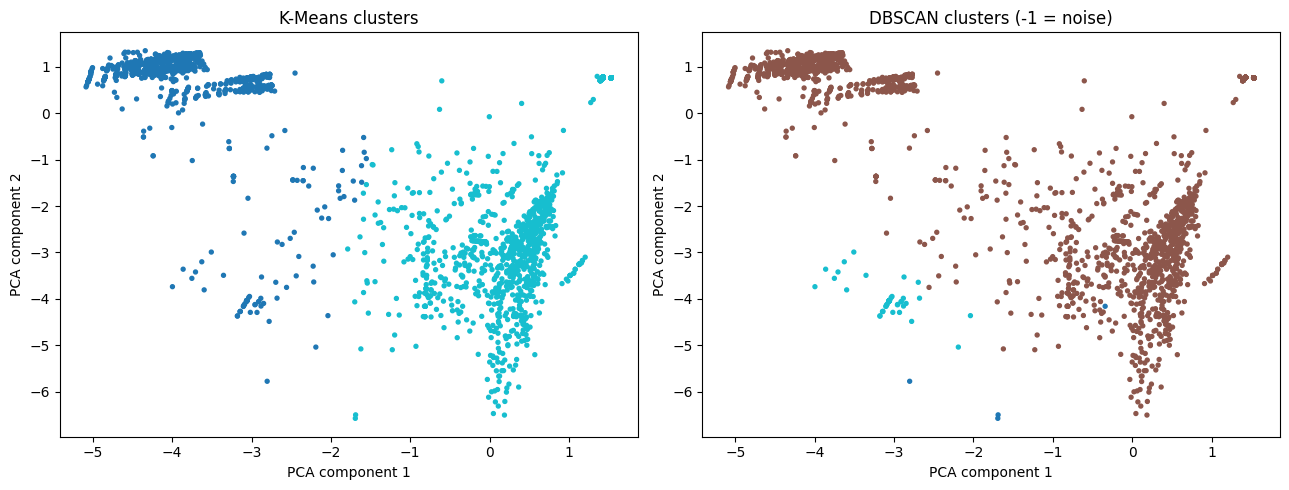

Variance explained by 2 PCA components: 0.771


In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=kmeans_labels, s=8, cmap="tab10")
axes[0].set_title("K-Means clusters")
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=dbscan_labels, s=8, cmap="tab10")
axes[1].set_title("DBSCAN clusters (-1 = noise)")
for ax in axes:
    ax.set_xlabel("PCA component 1")
    ax.set_ylabel("PCA component 2")
plt.tight_layout()
plt.show()
print("Variance explained by 2 PCA components:", round(pca.explained_variance_ratio_.sum(), 3))

## Step 7 - Evaluate cautiously using the hidden reference labels

Clustering is unsupervised, so we did not train with `y_reference`. Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI) compare cluster assignments with the known normal/attack reference. Higher is better, but these metrics do not prove operational usefulness. For DBSCAN, noise points count as one assignment group in these metrics.

In [ ]:
def safe_silhouette(X, labels, sample_size=1000):
    # Silhouette requires at least 2 clusters and fewer clusters than samples.
    non_noise = labels != -1
    labels_nn = labels[non_noise]
    X_nn = X[non_noise]
    if len(set(labels_nn)) < 2 or len(set(labels_nn)) >= len(labels_nn):
        return np.nan
    try:
        return silhouette_score(X_nn, labels_nn, sample_size=min(sample_size, len(labels_nn)), random_state=RANDOM_STATE)
    except Exception:
        return np.nan

results = pd.DataFrame([
    {"method": "K-Means", "clusters_excluding_noise": len(set(kmeans_labels)),
     "noise_points": 0, "ARI_vs_reference": adjusted_rand_score(y_reference, kmeans_labels),
     "NMI_vs_reference": normalized_mutual_info_score(y_reference, kmeans_labels),
     "silhouette": safe_silhouette(X, kmeans_labels)},
    {"method": "DBSCAN", "clusters_excluding_noise": len(set(dbscan_labels)) - (1 if -1 in set(dbscan_labels) else 0),
     "noise_points": int(np.sum(dbscan_labels == -1)), "ARI_vs_reference": adjusted_rand_score(y_reference, dbscan_labels),
     "NMI_vs_reference": normalized_mutual_info_score(y_reference, dbscan_labels),
     "silhouette": safe_silhouette(X, dbscan_labels)}
])
display(results.round(3))

,method,clusters_excluding_noise,noise_points,ARI_vs_reference,NMI_vs_reference,silhouette
0,K-Means,2,0,-0.067,0.031,0.658
1,DBSCAN,2,4,0.061,0.051,0.699


## Step 8 — Analyst investigation: what is inside each cluster?

Do not assume every cluster is an attack. Inspect the normal/attack composition **after** clustering, then review examples from clusters that have a high attack share or many DBSCAN noise points.

In [ ]:
inspection = pd.DataFrame({
    "cluster_kmeans": kmeans_labels,
    "cluster_dbscan": dbscan_labels,
    "reference_is_attack": y_reference
})

print("Attack share by K-Means cluster (reference labels used only for analysis):")
display(inspection.groupby("cluster_kmeans")["reference_is_attack"].agg(["count", "mean"]).rename(columns={"mean":"attack_share"}).round(3))

print("Attack share by DBSCAN cluster, including -1=noise:")
display(inspection.groupby("cluster_dbscan")["reference_is_attack"].agg(["count", "mean"]).rename(columns={"mean":"attack_share"}).round(3))

# Show a few records from the largest DBSCAN noise group for analyst review.
noise_idx = np.where(dbscan_labels == -1)[0][:10]
if len(noise_idx):
    print("Example DBSCAN noise observations (not automatically malicious):")
    display(X_raw.iloc[noise_idx])
else:
    print("No noise points with current parameters. Try changing EPS or MIN_SAMPLES.")

Attack share by K-Means cluster (reference labels used only for analysis):


,count,attack_share
cluster_kmeans,,
0,1160,0.923
1,3840,0.769


Attack share by DBSCAN cluster, including -1=noise:


,count,attack_share
cluster_dbscan,,
-1,4,0.500
0,4944,0.813
1,52,0.058


Example DBSCAN noise observations (not automatically malicious):


,duration,src_bytes,dst_bytes,count,srv_count,serror_rate,same_srv_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate
229604,3.135494,4.948760,7.611348,0.693147,0.693147,0.0,1.0,0.693147,0.693147,1.00
245881,4.454347,5.627621,6.542472,0.693147,0.693147,0.0,1.0,0.693147,0.693147,1.00
162088,6.234411,5.521461,5.602119,0.693147,1.098612,0.0,1.0,5.545177,5.521461,0.98
343535,4.110874,4.836282,5.192957,0.693147,0.693147,1.0,1.0,0.693147,0.693147,1.00


## Activities
1. Run K-Means with `K=3` and `K=4`. Record cluster sizes, Silhouette Score and ARI.
2. Run DBSCAN with `(eps, min_samples)` = `(1.5, 5)`, `(2.5, 10)`, and `(3.0, 15)`. Record the number of clusters and noise percentage.